# **1.1 Ticker selection and data acquisition**

In [1]:
# Import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Part 1: Extract S&P 500 tickers from Wikipedia using Pandas
# User-Agent is required to avoid HTTP 403 blocking from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

print('Total tickers extracted:', len(tickers))
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)


Total tickers extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [3]:
# Load Daily Market Data via yfinance

# Period: 2021-01-01 to 2025-01-01 (end exclusive)

start = '2021-01-01'
end = '2025-01-01'

# Download S&P 500 stock data
df = yf.download(tickers, start=start, end=end, auto_adjust=False)

# Extract required columns
daily_close = df['Close']
daily_adjusted = df['Adj Close']
daily_volume = df['Volume']

# Download S&P 500 benchmark
market_data = yf.download('^GSPC', start=start, end=end, auto_adjust=False)

print('Close Shape:', daily_close.shape)
print('Adjusted Close Shape:', daily_adjusted.shape)
print('Volume Shape:', daily_volume.shape)
print('Benchmark Shape:', market_data.shape)

daily_adjusted.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'Q', 'SNDK', 'FDXF', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed

Close Shape: (1005, 503)
Adjusted Close Shape: (1005, 503)
Volume Shape: (1005, 503)
Benchmark Shape: (1005, 6)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009125,125.537117,84.219131,139.149994,97.269691,33.186359,232.029327,485.339996,132.622574,42.189487,...,26.124495,102.852089,54.757385,33.042763,92.602486,221.160004,95.016197,141.603363,378.130005,152.952042
2021-01-05,114.941261,127.089218,85.090012,148.300003,98.473190,33.319485,233.350250,485.690002,134.993134,43.010094,...,26.371328,106.017532,54.223648,34.635178,92.491020,229.750000,95.025154,144.053360,380.570007,154.017899
2021-01-06,118.093224,122.811195,84.354973,142.770004,98.268158,34.783871,235.901566,466.309998,135.601715,44.752831,...,26.506683,106.652542,55.424545,35.518978,96.392433,226.889999,95.545967,148.158371,394.820007,156.280502
2021-01-07,121.235596,127.001915,85.257812,151.270004,99.222054,34.460564,238.127258,477.739990,141.332718,44.355217,...,26.761482,105.594177,54.340412,35.797646,100.767570,239.479996,94.818649,147.280075,409.100006,156.140289
2021-01-08,122.100479,128.098114,85.705223,149.770004,99.498383,34.650742,238.995819,485.100006,142.359070,44.473656,...,26.578352,104.901443,54.840775,36.195766,99.745766,241.449997,96.210396,146.956497,405.470001,157.178085


In [4]:
# Get the original data extracted to a csv file to download
sp500_df.to_csv('sp500_ticker_list.csv', index=False)
daily_adjusted.to_csv('daily_adj_close.csv')

#### Added: provenance, snapshots, package versions, evidence (1.1)

In [5]:
import datetime, sys, importlib.metadata as md

RETRIEVAL_DATE = datetime.date.today().isoformat()
print('Ticker list + prices retrieved on:', RETRIEVAL_DATE)

# Preserved snapshots (commit these to GitHub). Reload later with e.g.
# pd.read_csv('snapshot_daily_adj_close.csv', index_col=0, parse_dates=True)
sp500_df.assign(Retrieval_Date=RETRIEVAL_DATE).to_csv('sp500_ticker_list_snapshot.csv', index=False)
daily_close.to_csv('snapshot_daily_close.csv')
daily_adjusted.to_csv('snapshot_daily_adj_close.csv')
daily_volume.to_csv('snapshot_daily_volume.csv')
market_data.to_csv('snapshot_gspc.csv')   # multi-row header: read with header=[0, 1]

pkgs = ['pandas', 'numpy', 'yfinance', 'scikit-learn', 'scipy', 'matplotlib', 'seaborn']
with open('requirements.txt', 'w') as f:
    f.write(f'# python {sys.version.split()[0]}; data retrieved {RETRIEVAL_DATE}\n')
    for p in pkgs:
        f.write(f'{p}=={md.version(p)}\n')
print(open('requirements.txt').read())

# Survivorship-bias evidence: how much of TODAY's list was not in the index in 2021?
if 'Date added' in sp500_df.columns:
    added = pd.to_datetime(sp500_df['Date added'], errors='coerce')
    n_late = int((added > pd.Timestamp(start)).sum())
    print(f'{n_late} of {len(sp500_df)} current constituents were added to the index '
          f'after {start}; stocks that left the index before retrieval are absent.')

Ticker list + prices retrieved on: 2026-11-25
# python 3.13.18; data retrieved 2026-11-25
pandas==2.2.3
numpy==2.4.6
yfinance==0.2.66
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
seaborn==0.13.2

89 of 503 current constituents were added to the index after 2021-01-01; stocks that left the index before retrieval are absent.


In [6]:
# Part 3: Transpose DataFrame
# Rows = tickers, Columns = dates

df1 = daily_adjusted.T

print('Shape after transpose:', df1.shape)

df1

Shape after transpose: (503, 1005)


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009125,114.941261,118.093224,121.235596,122.100479,123.147919,122.014000,122.023575,121.110641,121.283646,...,134.353806,130.957047,131.134262,132.433884,132.522507,133.999344,133.733521,133.447998,132.345276,132.510986
AAPL,125.537117,127.089218,122.811195,127.001915,128.098114,125.119949,124.945366,126.972786,125.052086,123.335045,...,251.462662,246.075928,247.802032,252.464676,253.238449,256.145142,256.958588,253.555878,250.192856,248.427048
ABBV,84.219131,85.090012,84.354973,85.257812,85.705223,87.103409,87.710617,89.843864,90.231857,89.334641,...,164.530716,162.316711,160.909485,164.718338,167.354507,168.864914,168.114410,166.998001,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269691,98.473190,98.268158,99.222054,99.498383,98.811958,97.029007,99.979813,98.493988,99.621773,...,108.486847,107.184517,107.653732,109.387001,109.463600,109.894531,110.382912,110.114769,108.017616,108.314476
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
XYZ,221.160004,229.750000,226.889999,239.479996,241.449997,225.500000,227.520004,230.919998,232.789993,227.750000,...,94.550003,87.300003,87.639999,89.650002,89.290001,91.080002,91.480003,88.970001,87.480003,84.989998
YUM,95.016197,95.025154,95.545967,94.818649,96.210396,96.677292,96.677292,96.210396,96.776093,95.734505,...,130.267380,127.105690,126.042130,127.975891,129.426193,130.528442,131.495316,130.750824,129.097473,129.716263
ZBH,141.603363,144.053360,148.158371,147.280075,146.956497,147.002716,147.770050,150.654678,150.349548,148.038193,...,105.912399,103.756111,103.707100,104.991081,104.697037,105.167503,105.118492,104.746040,103.537773,103.763702


# **1.2 Data validation and alignment**

In [7]:
# Part 3: Identify and Remove Invalid Data

print('Before cleaning:', df1.shape)

initial_count = df1.shape[0]

# 1. Check duplicate dates
print('Duplicate dates:', df1.columns.duplicated().sum())

# 2. Check missing values
print('Missing values:', df1.isna().sum().sum())

# 3. Check nonpositive prices
print('Nonpositive prices:', (df1 <= 0).sum().sum())

# 4. Replace invalid prices with NaN
df1 = df1.mask(df1 <= 0)

# 5. Drop tickers with entirely missing prices
df1 = df1.dropna(how='all')

# 6. Retain tickers with at least 80% valid observations
min_cols = int(np.ceil(0.8 * df1.shape[1]))
df1 = df1.dropna(thresh=min_cols)

# 7. Do not fill missing prices
# Missing values remain NaN

print('After cleaning:', df1.shape)
print('Rows (tickers) removed:', initial_count - df1.shape[0])

df1.head()

Before cleaning: (503, 1005)
Duplicate dates: 0
Missing values: 9211
Nonpositive prices: 0
After cleaning: (492, 1005)
Rows (tickers) removed: 11


Date,2021-01-04,2021-01-05,2021-01-06,2021-01-07,2021-01-08,2021-01-11,2021-01-12,2021-01-13,2021-01-14,2021-01-15,...,2024-12-17,2024-12-18,2024-12-19,2024-12-20,2024-12-23,2024-12-24,2024-12-26,2024-12-27,2024-12-30,2024-12-31
Ticker,,,,,,,,,,,,,,,,,,,,,
A,114.009125,114.941261,118.093224,121.235596,122.100479,123.147919,122.014000,122.023575,121.110641,121.283646,...,134.353806,130.957047,131.134262,132.433884,132.522507,133.999344,133.733521,133.447998,132.345276,132.510986
AAPL,125.537117,127.089218,122.811195,127.001915,128.098114,125.119949,124.945366,126.972786,125.052086,123.335045,...,251.462662,246.075928,247.802032,252.464676,253.238449,256.145142,256.958588,253.555878,250.192856,248.427048
ABBV,84.219131,85.090012,84.354973,85.257812,85.705223,87.103409,87.710617,89.843864,90.231857,89.334641,...,164.530716,162.316711,160.909485,164.718338,167.354507,168.864914,168.114410,166.998001,165.299973,166.707184
ABNB,139.149994,148.300003,142.770004,151.270004,149.770004,148.130005,160.800003,169.990005,180.500000,169.270004,...,132.240005,127.540001,129.350006,134.210007,134.520004,134.990005,135.320007,133.384995,131.809998,131.410004
ABT,97.269691,98.473190,98.268158,99.222054,99.498383,98.811958,97.029007,99.979813,98.493988,99.621773,...,108.486847,107.184517,107.653732,109.387001,109.463600,109.894531,110.382912,110.114769,108.017616,108.314476


In [8]:
# Show tickers with missing values and their percentages
missing_count = df1.isna().sum(axis=1)
missing_percentage = (missing_count / df1.shape[1]) * 100

missing_report = pd.DataFrame({
    'Missing_Values': missing_count,
    'Missing_Percentage': missing_percentage.round(2)
})

# Display only tickers with missing values
missing_report = missing_report[missing_report['Missing_Values'] > 0]

print("Tickers with missing values:", len(missing_report))
display(missing_report.sort_values('Missing_Percentage', ascending=False))

Tickers with missing values: 4


,Missing_Values,Missing_Percentage
Ticker,,
HOOD,143,14.23
APP,70,6.97
COIN,69,6.87
EXE,26,2.59


In [9]:
# 1. Check volume errors
volume = daily_volume[df1.index]

print("Missing volume:", volume.isna().sum().sum())
print("Negative volume:", (volume < 0).sum().sum())
print("Zero volume:", (volume == 0).sum().sum())


# 2. Check unequal stock histories
history = pd.DataFrame({
    "First_Date": df1.T.apply(lambda x: x.first_valid_index()),
    "Last_Date": df1.T.apply(lambda x: x.last_valid_index()),
    "Valid_Days": df1.notna().sum(axis=1)
})

display(history.head())


# 3. Check corporate actions
# Compare Close and Adjusted Close prices

close = daily_close[df1.index]
adjusted = daily_adjusted[df1.index]

adjustment_ratio = adjusted / close.replace(0, np.nan)

print("Shares with price adjustments:",
      (adjustment_ratio.sub(1).abs() > 0.001).any().sum())


# 4. Record excluded shares
excluded_tickers = daily_adjusted.columns.difference(df1.index)

print("Excluded shares:", len(excluded_tickers))
print("Excluded tickers:", excluded_tickers.tolist())

Missing volume: 308
Negative volume: 0
Zero volume: 451


,First_Date,Last_Date,Valid_Days
Ticker,,,
A,2021-01-04,2024-12-31,1005
AAPL,2021-01-04,2024-12-31,1005
ABBV,2021-01-04,2024-12-31,1005
ABNB,2021-01-04,2024-12-31,1005
ABT,2021-01-04,2024-12-31,1005


Shares with price adjustments: 399
Excluded shares: 11
Excluded tickers: ['CEG', 'FDXF', 'GEHC', 'GEV', 'HONA', 'Q', 'RDDT', 'SNDK', 'SOLV', 'VLTO', 'VYLR']


#### Added: exclusion log with reasons and corporate-action / split check (1.2)

In [10]:
# --- exclusion log -----------------------------------------------------------
failed = daily_adjusted.columns[daily_adjusted.isna().all()]
exclusion_log = pd.DataFrame({'Ticker': list(excluded_tickers)})
exclusion_log['Valid_daily_prices'] = (
    daily_adjusted[excluded_tickers].notna().sum().reindex(excluded_tickers).values)
exclusion_log['Reason'] = np.where(
    exclusion_log['Ticker'].isin(failed),
    'No price data returned by Yahoo (all NaN)',
    'Fewer than 80% valid daily prices (short history)')

# retained shares with unequal histories (kept, NOT filled)
retained_gaps = history[history['Valid_Days'] < df1.shape[1]].copy()
retained_gaps['Reason'] = 'Retained: unequal history, missing days left as NaN'
log_out = pd.concat([
    exclusion_log.rename(columns={'Valid_daily_prices': 'Valid_Days'}).set_index('Ticker'),
    retained_gaps[['Valid_Days', 'Reason']]])
log_out.to_csv('inclusion_exclusion_log.csv')
display(log_out)

# --- corporate-action check (replaces "399 shares with adjustments") ----------
# Yahoo's Close is split-adjusted but not dividend-adjusted. Test that rather than assume it.
close_r = daily_close[df1.index]
adj_r = daily_adjusted[df1.index]
ratio_step = np.log(adj_r / close_r).diff().abs()      # jumps in Adj/Close = distributions or splits
big_move = (close_r.pct_change(fill_method=None).abs() > 0.40).sum()   # >40% one-day moves
flagged = ratio_step.max()[ratio_step.max() > 0.05].index.union(big_move[big_move > 0].index)
print('Shares flagged for split/large-distribution review:', len(flagged))

split_log = []
for t in flagged:
    try:
        s = yf.Ticker(t).splits
        s.index = s.index.tz_localize(None)
        s = s[(s.index >= start) & (s.index < end)]
        for d, r in s.items():
            split_log.append({'Ticker': t, 'Date': d.date(), 'Split_ratio': r})
    except Exception as e:
        split_log.append({'Ticker': t, 'Date': None, 'Split_ratio': f'lookup failed: {e}'})
split_log = pd.DataFrame(split_log)
split_log.to_csv('split_check_log.csv', index=False)
display(split_log)
# Interpret: if Close shows no unexplained jump on split dates, Close and Volume are on a
# compatible (split-adjusted) basis, which is what Monetary = Close x Volume needs.

,Valid_Days,Reason
Ticker,,
CEG,742,Fewer than 80% valid daily prices (short history)
FDXF,0,No price data returned by Yahoo (all NaN)
GEHC,513,Fewer than 80% valid daily prices (short history)
GEV,193,Fewer than 80% valid daily prices (short history)
HONA,0,No price data returned by Yahoo (all NaN)
Q,0,No price data returned by Yahoo (all NaN)
RDDT,197,Fewer than 80% valid daily prices (short history)
SNDK,0,No price data returned by Yahoo (all NaN)
SOLV,194,Fewer than 80% valid daily prices (short history)


Shares flagged for split/large-distribution review: 10


,Ticker,Date,Split_ratio
0,DXCM,2022-06-13,4.0


In [11]:
# 1. Resample adjusted share prices to weekly frequency
weekly_prices = df1.T.resample("W-FRI").last()

# 2. Resample benchmark prices to weekly frequency
market_prices = market_data["Adj Close"].squeeze()
market_weekly = market_prices.resample("W-FRI").last()

# 3. Calculate weekly returns for alignment
weekly_returns = weekly_prices.pct_change(fill_method=None)
market_returns = market_weekly.pct_change(fill_method=None)

# 4. Align shares and benchmark using identical week labels
common_weeks = weekly_returns.index.intersection(market_returns.index)

weekly_returns = weekly_returns.loc[common_weeks]
market_returns = market_returns.loc[common_weeks]

# 5. Verify alignment
print("Share weeks:", len(weekly_returns))
print("Benchmark weeks:", len(market_returns))

print("Week labels aligned:",
      weekly_returns.index.equals(market_returns.index))

# 6. Check missing weekly returns
print("Missing share returns:", weekly_returns.isna().sum().sum())
print("Missing benchmark returns:", market_returns.isna().sum())

weekly_returns.head()

Share weeks: 209
Benchmark weeks: 209
Week labels aligned: True
Missing share returns: 554
Missing benchmark returns: 1


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025764,-0.025681,-0.012165,0.053453,-0.036133,-0.056741,-0.004946,0.007361,0.009249,-0.038963
2021-01-22,0.000951,0.093834,0.003076,0.074437,0.013837,-0.039781,0.004416,0.031348,-0.013756,0.011877,...,0.021218,0.011484,-0.003079,-0.009605,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012522
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053028,-0.053199,...,-0.060825,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052292,-0.045587,-0.051389,-0.055593
2021-02-05,0.025048,0.037923,0.060987,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065787,...,0.102918,0.175425,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040476,0.049713,0.032609


In [12]:
# Check missing returns after the first week

missing_after_first = weekly_returns.iloc[1:].isna().sum()

print("Missing returns after first week:", missing_after_first.sum())

print("Shares affected:", (missing_after_first > 0).sum())

# Calculate weekly coverage
coverage = weekly_returns.iloc[1:].notna().mean() * 100

print("Shares below 80% coverage:", (coverage < 80).sum())

# Display affected shares
missing_report = pd.DataFrame({
    "Missing_Weeks": missing_after_first,
    "Coverage_Percent": coverage
})

display(missing_report[missing_report["Missing_Weeks"] > 0])

Missing returns after first week: 62
Shares affected: 4
Shares below 80% coverage: 0


,Missing_Weeks,Coverage_Percent
Ticker,,
APP,14,93.269231
COIN,14,93.269231
EXE,5,97.596154
HOOD,29,86.057692


In [13]:
# Part 7: Final Missing Data Validation

# Retain all shares meeting 80% weekly coverage
valid_shares = coverage[coverage >= 80].index

weekly_returns = weekly_returns[valid_shares]

# Save missing data report
missing_report.to_csv("missing_weekly_returns_report.csv")

print("Final shares retained:", len(valid_shares))
print("Missing returns after first week:",
      weekly_returns.iloc[1:].isna().sum().sum())

print("Weekly benchmark alignment:",
      weekly_returns.index.equals(market_returns.index))

Final shares retained: 492
Missing returns after first week: 62
Weekly benchmark alignment: True


In [14]:
# Download the cleaned & validated data to a csv file
weekly_returns.to_csv('weekly_returns.csv')
market_returns.to_csv('market_returns.csv')

# **1.3** **Weekly return and weekly beta**

# 1.3.1 Mean weekly return

In [15]:
# Part 8: Calculate Mean Weekly Returns

# 1. Calculate arithmetic mean weekly return for each share
mean_weekly_returns = weekly_returns.mean()

# 2. Store results in a DataFrame
mean_returns_df = pd.DataFrame({
    'Share': mean_weekly_returns.index,
    'Mean_Weekly_Return': mean_weekly_returns.values
})

# 3. Display results
print('Total shares:', len(mean_returns_df))

mean_returns_df.head(10)

# Check missing mean returns
print('Missing mean returns:',
      mean_returns_df['Mean_Weekly_Return'].isna().sum())

# Save results for clustering
mean_returns_df.to_csv('mean_weekly_returns.csv', index=False)

Total shares: 492
Missing mean returns: 0


# 1.3.2 Weekly beta

In [16]:
# Part 9: Calculate Weekly Beta

# 1. Exclude incomplete first and final calendar weeks
# Retain normal holiday-shortened weeks

weekly_returns_beta = weekly_returns.loc[
    (weekly_returns.index >= '2021-01-11') &
    (weekly_returns.index < '2025-01-01')
]

market_returns_beta = market_returns.loc[weekly_returns_beta.index]


# 2. Calculate weekly beta for each share
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):

    results = []

    for share in weekly_returns.columns:

        # Align share and market returns
        paired = pd.concat([
            weekly_returns[share].rename("Share"),
            market_returns.rename("Market")
        ], axis=1).replace([np.inf, -np.inf], np.nan).dropna()

        # Calculate beta
        beta = np.nan

        if len(paired) >= min_weeks and paired["Market"].var() > 0:

            beta = (
                paired["Share"].cov(paired["Market"]) /
                paired["Market"].var()
            )

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(results).set_index("Share")


# 3. Calculate beta
beta_df = calculate_weekly_beta(
    weekly_returns_beta,
    market_returns_beta
)

# 4. Display results
print("Total shares:", len(beta_df))
print("Missing beta values:", beta_df["Beta"].isna().sum())

beta_df.head(10)

Total shares: 492
Missing beta values: 0


,Beta,Paired_weeks
Share,,
A,1.074724,207
AAPL,1.174835,207
ABBV,0.425365,207
ABNB,1.472709,207
ABT,0.583542,207
ACGL,0.586638,207
ACN,1.143300,207
ADBE,1.553525,207
ADI,1.131969,207


In [17]:
# Recalculate and save mean weekly returns and beta for clustering

# 1. Use verified weekly returns (exclude incomplete boundary weeks)
weekly_returns_beta = weekly_returns.loc[
    (weekly_returns.index >= '2021-01-11') &
    (weekly_returns.index < '2025-01-01')
]

market_returns_beta = market_returns.loc[weekly_returns_beta.index]

# 2. Recalculate mean weekly returns
mean_returns_df = pd.DataFrame({
    'Share': weekly_returns_beta.columns,
    'Mean_Weekly_Return': weekly_returns_beta.mean().values
})

# 3. Recalculate weekly beta
beta_df = calculate_weekly_beta(
    weekly_returns_beta,
    market_returns_beta
)

# 4. Save results for clustering
mean_returns_df.to_csv('mean_weekly_returns.csv', index=False)
beta_df.to_csv('weekly_beta.csv')

# 5. Verify results
print("Total shares:", len(beta_df))
print("Missing beta values:", beta_df['Beta'].isna().sum())
print("Aligned weekly observations:", len(weekly_returns_beta))

beta_df.head(10)

Total shares: 492
Missing beta values: 0
Aligned weekly observations: 207


,Beta,Paired_weeks
Share,,
A,1.074724,207
AAPL,1.174835,207
ABBV,0.425365,207
ABNB,1.472709,207
ABT,0.583542,207
ACGL,0.586638,207
ACN,1.143300,207
ADBE,1.553525,207
ADI,1.131969,207


In [18]:
# Verify weekly returns do not span missing weeks

# Recalculate returns without filling missing prices
weekly_returns_verified = weekly_prices.pct_change(fill_method=None)

# Check for differences
print("Incorrect returns:",
      (weekly_returns.fillna(0) !=
       weekly_returns_verified.loc[weekly_returns.index].fillna(0)).sum().sum())

# Update weekly returns
weekly_returns = weekly_returns_verified.loc[weekly_returns.index]

Incorrect returns: 0


In [19]:
print(beta_df[['Beta', 'Paired_weeks']].head(10))
print("Minimum paired weeks:", beta_df['Paired_weeks'].min())
print("Maximum paired weeks:", beta_df['Paired_weeks'].max())

           Beta  Paired_weeks
Share                        
A      1.074724           207
AAPL   1.174835           207
ABBV   0.425365           207
ABNB   1.472709           207
ABT    0.583542           207
ACGL   0.586638           207
ACN    1.143300           207
ADBE   1.553525           207
ADI    1.131969           207
ADM    0.548877           207
Minimum paired weeks: 178
Maximum paired weeks: 207


#### Added: weekly observation counts and independent beta / return checks (1.3)

In [20]:
weekly_obs = weekly_returns_beta.notna().sum()
mean_returns_df['Weekly_obs'] = mean_returns_df['Share'].map(weekly_obs)
print('Weekly return observations per share: min', weekly_obs.min(), 'max', weekly_obs.max())

# independent beta check: least-squares slope should equal cov/var
diffs = []
for s in beta_df.index:
    p = pd.concat([weekly_returns_beta[s], market_returns_beta], axis=1).dropna()
    diffs.append(np.polyfit(p.iloc[:, 1], p.iloc[:, 0], 1)[0])
print('Max |beta(cov/var) - beta(OLS slope)|:',
      float(np.max(np.abs(np.array(diffs) - beta_df['Beta'].values))))

# independent weekly-return check for one share, computed by hand from weekly prices
s = 'AAPL'
wp = weekly_prices[s]
manual = wp.iloc[1:].values / wp.iloc[:-1].values - 1
print('Manual vs pipeline weekly returns (AAPL) match:',
      np.allclose(manual, weekly_returns[s].iloc[1:].values, equal_nan=True))
print('Benchmark weeks in beta sample:', len(market_returns_beta),
      '| first:', market_returns_beta.index.min().date(),
      '| last:', market_returns_beta.index.max().date())

Weekly return observations per share: min 178 max 207
Max |beta(cov/var) - beta(OLS slope)|: 5.773159728050814e-15
Manual vs pipeline weekly returns (AAPL) match: True
Benchmark weeks in beta sample: 207 | first: 2021-01-15 | last: 2024-12-27


# 1.4 Adapted RFM Calculations

In [21]:
# 1. Use volume data for retained shares
volume = daily_volume[df1.index]

# 2. Find the final common completed trading date
observation_date = volume.dropna(how='any').index.max()

# 3. Calculate the mean volume of the preceding 20 trading sessions
rolling_mean = volume.shift(1).rolling(window=20, min_periods=20).mean()

# 4. Identify unusually high volume days
high_volume = volume > (2 * rolling_mean)

# 5. Select the latest 60 trading sessions
volume_60 = volume.loc[:observation_date].tail(60)
high_volume_60 = high_volume.loc[volume_60.index]

print("Observation date:", observation_date)
print("Trading sessions:", len(volume_60))
print("Shares:", len(high_volume_60.columns))

high_volume_60.head()

Observation date: 2024-12-31 00:00:00
Trading sessions: 60
Shares: 492


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2024-10-07,False,False,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-10-08,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-10-09,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-10-10,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2024-10-11,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


#### Added: zero / missing volume diagnostics (1.2, 1.4)

In [22]:
# Zero / missing volume: where does it sit, and does it affect R, F or M?
zero_total = (volume == 0).sum()
zero_total = zero_total[zero_total > 0].sort_values(ascending=False)
print('Shares with zero-volume days (whole history):', len(zero_total))
display(zero_total.head(15))

span = volume.loc[:observation_date].tail(80)      # 20 baseline sessions + 60 window
zero_in_span = (span == 0).sum()
zero_in_span = zero_in_span[zero_in_span > 0]
print('Shares with zero volume inside the 80-session RFM span:', len(zero_in_span))
display(zero_in_span)

# Zero volume in a baseline lowers the 20-day mean and can create false events
base_has_zero = (volume.shift(1) == 0).astype(int).rolling(20).sum() > 0
print('High-volume events whose baseline contained a zero-volume day:',
      int((high_volume & base_has_zero).sum().sum()))
# Document the decision: if the counts are 0 in the span, say zero volume does not affect
# F or M; if not, state how those shares were treated.

Shares with zero-volume days (whole history): 2


,0
Ticker,
SW,424
FERG,27


Shares with zero volume inside the 80-session RFM span: 0


,0
Ticker,


High-volume events whose baseline contained a zero-volume day: 155


# 1.4.1 Recency (R)

In [23]:
# Part 2: Calculate Recency

recency = {}

for share in high_volume.columns:

    # Find qualifying high-volume dates
    event_dates = high_volume.index[
        high_volume[share] &
        volume[share].notna() &
        rolling_mean[share].notna() &
        (high_volume.index <= observation_date)
    ]

    # Calculate calendar days since the latest event
    if len(event_dates) > 0:
        recency[share] = (observation_date - event_dates[-1]).days
    else:
        recency[share] = np.nan

# Store results
recency_df = pd.DataFrame.from_dict(
    recency, orient='index', columns=['Recency']
)

print("Shares with missing Recency:", recency_df['Recency'].isna().sum())

recency_df.head(10)

Shares with missing Recency: 0


,Recency
A,11
AAPL,11
ABBV,11
ABNB,11
ABT,11
ACGL,11
ACN,11
ADBE,18
ADI,36
ADM,11


# 1.4.2 Frequency (F)

In [24]:
# Part 3: Calculate Frequency

# Count qualifying high-volume days in the latest 60 trading sessions
frequency = high_volume_60.sum()

# Store results
frequency_df = pd.DataFrame({
    'Frequency': frequency
})

# Verify results
print("Total shares:", len(frequency_df))
print("Maximum frequency:", frequency_df['Frequency'].max())
print("Minimum frequency:", frequency_df['Frequency'].min())

frequency_df.head(10)

Total shares: 492
Maximum frequency: 8
Minimum frequency: 0


,Frequency
Ticker,
A,2
AAPL,2
ABBV,3
ABNB,3
ABT,1
ACGL,4
ACN,2
ADBE,3
ADI,1


# 1.4.3 Monitory (M)

In [25]:
# Part 4: Calculate Monetary

# 1. Select Close prices for the latest 60 trading sessions
close_60 = daily_close.loc[volume_60.index, volume_60.columns]

# 2. Calculate approximate daily traded value
daily_traded_value = close_60 * volume_60

# 3. Sum traded values over 60 sessions
monetary = daily_traded_value.sum(min_count=60)

# 4. Store results
monetary_df = pd.DataFrame({
    'Monetary': monetary
})

# 5. Verify results
print("Total shares:", len(monetary_df))
print("Missing Monetary values:", monetary_df['Monetary'].isna().sum())

monetary_df.head(10)

Total shares: 492
Missing Monetary values: 0


,Monetary
Ticker,
A,1.400180e+10
AAPL,6.233034e+11
ABBV,6.837054e+10
ABNB,3.652850e+10
ABT,3.523027e+10
ACGL,1.196213e+10
ACN,5.199430e+10
ADBE,1.030403e+11
ADI,3.849918e+10


# 1.5 Metric interpretation and supporting evidence

In [26]:
# 1. Combine RFM features
rfm_df = recency_df.join([frequency_df, monetary_df])

# 2. Feature summary
print("RFM Feature Summary:")
display(rfm_df.describe())

print("\nMissing RFM Values:")
print(rfm_df.isna().sum())


# 3. Worked RFM example - ABBV
share = 'ABBV'

events = high_volume.index[
    high_volume[share] & (high_volume.index <= observation_date)
]

print("\nWorked Example:", share)
print("Observation Date:", observation_date.date())
print("Latest High Volume Date:",
      events[-1].date() if len(events) else "No Event")
print("Recency:", rfm_df.loc[share, 'Recency'], "calendar days")
print("Frequency:", rfm_df.loc[share, 'Frequency'], "days")
print("Monetary: $", format(rfm_df.loc[share, 'Monetary'], ',.2f'))


# 4. Validation checks
print("\nValidation Checks:")

print("20-session threshold aligned:",
      rolling_mean.equals(volume.shift(1).rolling(20, min_periods=20).mean()))

print("60 trading sessions:", len(volume_60))

print("Incomplete 60-session histories:",
      volume_60.isna().any().sum())

print("Insufficient 20-session baselines:",
      rolling_mean.loc[volume_60.index].isna().any().sum())

print("Shares with no qualifying event:",
      rfm_df['Recency'].isna().sum())

print("Invalid Frequency:",
      ((rfm_df['Frequency'] < 0) |
       (rfm_df['Frequency'] > 60)).sum())


# 5. Inclusion and exclusion log
rfm_valid = rfm_df.dropna()

excluded_rfm = rfm_df.index.difference(rfm_valid.index)

print("\nInclusion and Exclusion Log:")
print("Total shares:", len(rfm_df))
print("Included shares:", len(rfm_valid))
print("Excluded shares:", len(excluded_rfm))
print("Excluded tickers:", excluded_rfm.tolist())


# 6. Save valid RFM dataset
rfm_valid.to_csv("rfm_clustering_data.csv")

print("\nRFM dataset saved successfully.")

RFM Feature Summary:


,Recency,Frequency,Monetary
count,492.000000,492.000000,4.920000e+02
mean,20.493902,2.995935,3.974218e+10
std,21.303977,1.328055,1.286397e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025241e+10
50%,11.000000,3.000000,1.679667e+10
75%,18.000000,4.000000,3.253548e+10
max,222.000000,8.000000,1.847697e+12



Missing RFM Values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Worked Example: ABBV
Observation Date: 2024-12-31
Latest High Volume Date: 2024-12-20
Recency: 11 calendar days
Frequency: 3 days
Monetary: $ 68,370,537,641.66

Validation Checks:
20-session threshold aligned: True
60 trading sessions: 60
Incomplete 60-session histories: 0
Insufficient 20-session baselines: 0
Shares with no qualifying event: 0
Invalid Frequency: 0

Inclusion and Exclusion Log:
Total shares: 492
Included shares: 492
Excluded shares: 0
Excluded tickers: []

RFM dataset saved successfully.


#### Added: verified RFM - synthetic tests, brute-force check, fuller worked example (1.4, 1.5)

In [27]:
def flag_high_volume(v):
    base = v.shift(1).rolling(20, min_periods=20).mean()
    return v > 2 * base

def recency_from_flags(flags, obs):
    ev = flags.index[flags & (flags.index <= obs)]
    return (obs - ev[-1]).days if len(ev) else np.nan

dates = pd.bdate_range('2024-01-01', periods=24)
def make(v_on):
    v = pd.Series(1_000_000.0, index=dates)
    v.iloc[20] = v_on
    return v

# brief's examples: baseline 1M -> threshold 2M; 2.5M qualifies, 1.8M does not, exactly 2.0M does not
for vol, expected in [(2_500_000, True), (1_800_000, False), (2_000_000, False)]:
    assert flag_high_volume(make(vol)).iloc[20] == expected, vol
assert not flag_high_volume(make(9e9)).iloc[:20].any()   # no event without a 20-session baseline
# event on the observation date -> R = 0
v21 = make(2_500_000).iloc[:21]
assert recency_from_flags(flag_high_volume(v21), v21.index[-1]) == 0
# no event -> NaN, not 0
assert np.isnan(recency_from_flags(flag_high_volume(make(1_000_000)), dates[-1]))
print('Synthetic threshold / R=0 / no-event tests passed')

# brute-force loop recomputation vs the vectorised pipeline
def brute_force_rfm(share):
    v, c = volume[share], daily_close[share]
    n = v.index.get_loc(observation_date)
    events = []
    for i in range(20, n + 1):
        base = v.iloc[i - 20:i]
        if base.notna().all() and pd.notna(v.iloc[i]) and v.iloc[i] > 2 * base.mean():
            events.append(i)
    R = (observation_date - v.index[events[-1]]).days if events else np.nan
    F = sum(1 for i in events if i > n - 60)
    M = (c.iloc[n - 59:n + 1] * v.iloc[n - 59:n + 1]).sum()
    return R, F, M

rng = np.random.default_rng(42)
sample = set(rng.choice(rfm_df.index, 25, replace=False))
sample |= {rfm_df['Recency'].idxmax(), rfm_df['Frequency'].idxmax(), rfm_df['Frequency'].idxmin()}
bad = []
for s in sample:
    R, F, M = brute_force_rfm(s)
    got = rfm_df.loc[s]
    if not (np.isclose(R, got['Recency']) and F == got['Frequency'] and np.isclose(M, got['Monetary'])):
        bad.append(s)
print(f'Brute-force check on {len(sample)} shares (incl. extremes): mismatches = {bad}')

# fuller worked example for one share
share = 'ABBV'
ev_date = high_volume.index[high_volume[share] & (high_volume.index <= observation_date)][-1]
print('Latest event date:', ev_date.date(), '| volume:', f'{volume.loc[ev_date, share]:,.0f}',
      '| 20-session mean:', f'{rolling_mean.loc[ev_date, share]:,.0f}',
      '| threshold (2x):', f'{2 * rolling_mean.loc[ev_date, share]:,.0f}')
print('Qualifying days in the last 60 sessions:',
      [d.date().isoformat() for d in high_volume_60.index[high_volume_60[share]]])
display((close_60[share] * volume_60[share]).head(3).to_frame('Daily traded value (USD)'))

Synthetic threshold / R=0 / no-event tests passed
Brute-force check on 27 shares (incl. extremes): mismatches = []
Latest event date: 2024-12-20 | volume: 18,950,900 | 20-session mean: 6,293,830 | threshold (2x): 12,587,660
Qualifying days in the last 60 sessions: ['2024-10-30', '2024-11-11', '2024-12-20']


,Daily traded value (USD)
Date,
2024-10-07,9.745940e+08
2024-10-08,8.529112e+08
2024-10-09,8.722658e+08


# **2.1: Feature Preparation**

In [28]:
risk_return = mean_returns_df.set_index('Share')[['Mean_Weekly_Return']].join(
    beta_df[['Beta']]
)

rfm_features = rfm_df[['Recency', 'Frequency', 'Monetary']].copy()

# Retain shares with complete features in both matrices
common = risk_return.dropna().index.intersection(rfm_features.dropna().index)
risk_return = risk_return.loc[common]
rfm_features = rfm_features.loc[common]

print("Risk and Return:", risk_return.shape)
print("RFM:", rfm_features.shape)

Risk and Return: (492, 2)
RFM: (492, 3)



 Risk and Return
Skewness:
 Mean_Weekly_Return    0.937234
Beta                  1.247269
dtype: float64
Outliers:
 Mean_Weekly_Return    16
Beta                  12
dtype: int64


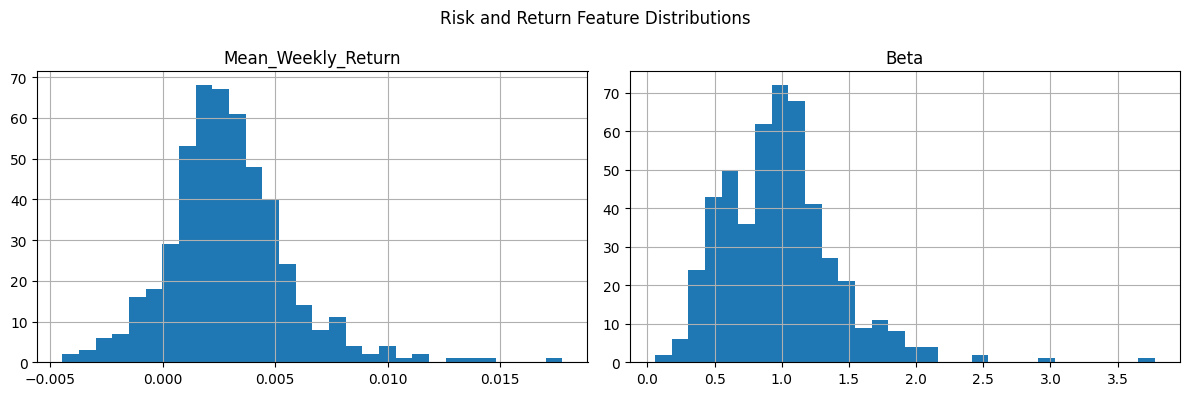


 RFM
Skewness:
 Recency       3.618971
Frequency     0.416061
Monetary     11.672945
dtype: float64
Outliers:
 Recency      96
Frequency     2
Monetary     47
dtype: int64


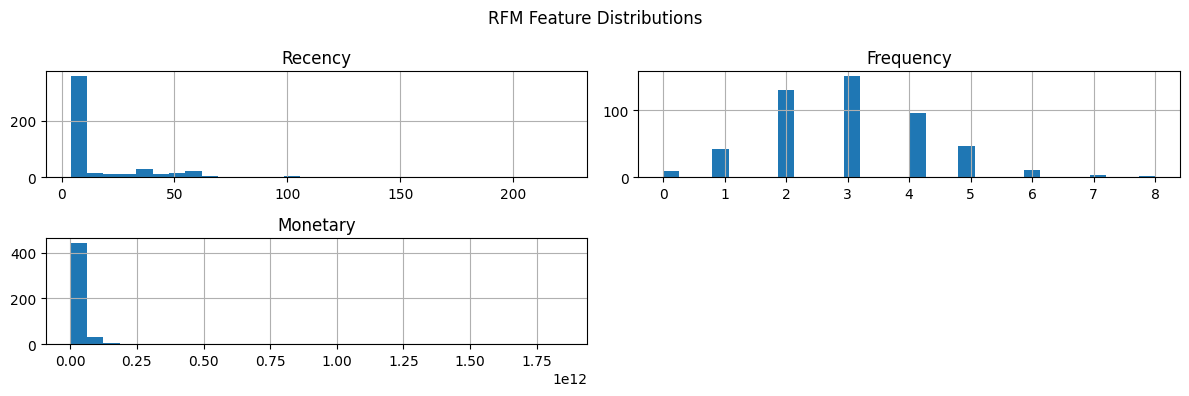

In [29]:
import matplotlib.pyplot as plt

for name, data in [('Risk and Return', risk_return),
                   ('RFM', rfm_features)]:

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    print("\n", name)
    print("Skewness:\n", data.skew())
    print("Outliers:\n", ((data < Q1 - 1.5*IQR) |
                          (data > Q3 + 1.5*IQR)).sum())

    data.hist(figsize=(12, 4), bins=30)
    plt.suptitle(name + " Feature Distributions")
    plt.tight_layout()
    plt.show()

In [30]:
import numpy as np
from sklearn.preprocessing import StandardScaler

rfm_prepared = rfm_features.copy()
rfm_prepared['Monetary'] = np.log1p(rfm_prepared['Monetary'])

risk_scaled = pd.DataFrame(
    StandardScaler().fit_transform(risk_return),
    index=risk_return.index,
    columns=risk_return.columns
)

rfm_scaled = pd.DataFrame(
    StandardScaler().fit_transform(rfm_prepared),
    index=rfm_prepared.index,
    columns=rfm_prepared.columns
)

print("Monetary skewness after log1p:",
      rfm_prepared['Monetary'].skew())

Monetary skewness after log1p: 1.070277165639877


In [31]:
from sklearn.cluster import AgglomerativeClustering, KMeans

# Initial baseline of 3 clusters
k = 3

for name, X in [('Risk and Return', risk_scaled),
                ('RFM', rfm_scaled)]:

    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    km = KMeans(n_clusters=k, random_state=42, n_init=10)

    agg_labels = agg.fit_predict(X) + 1
    km_labels = km.fit_predict(X) + 1

    print("\n", name)
    print("Agglomerative cluster sizes:")
    print(pd.Series(agg_labels).value_counts().sort_index())

    print("K-Means cluster sizes:")
    print(pd.Series(km_labels).value_counts().sort_index())

    if name == 'Risk and Return':
        risk_agg_labels = agg_labels
        risk_kmeans_labels = km_labels
    else:
        rfm_agg_labels = agg_labels
        rfm_kmeans_labels = km_labels


 Risk and Return
Agglomerative cluster sizes:
1    333
2     36
3    123
Name: count, dtype: int64
K-Means cluster sizes:
1    122
2    166
3    204
Name: count, dtype: int64

 RFM
Agglomerative cluster sizes:
1    252
2     93
3    147
Name: count, dtype: int64
K-Means cluster sizes:
1    154
2    275
3     63
Name: count, dtype: int64


# 2.2 Agglomerative clustering

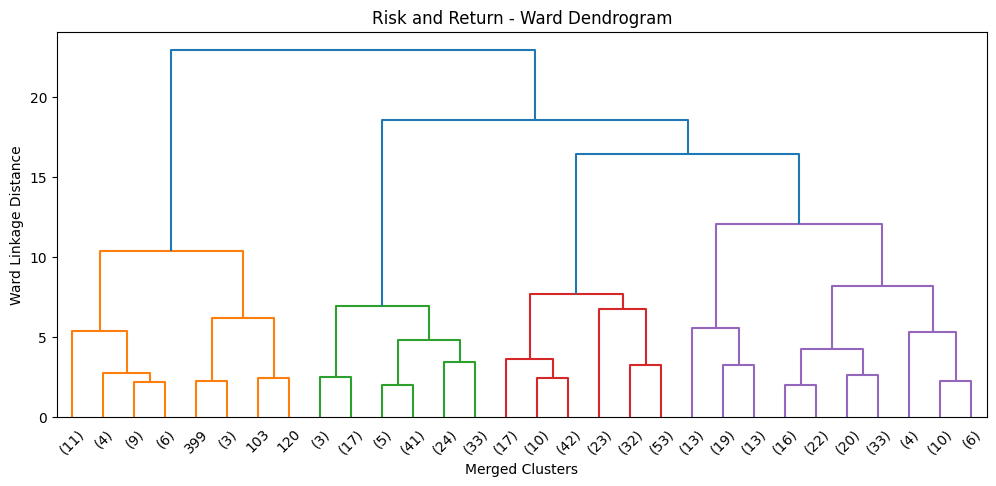

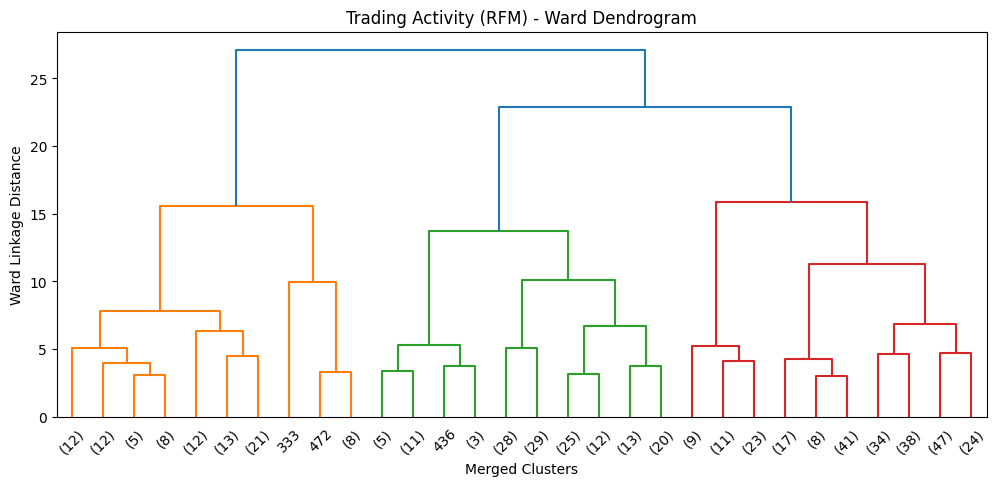

In [32]:
# Part 2.2 - Step 1: Dendrograms

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
import matplotlib.pyplot as plt

# Ward linkage for both matrices
risk_linkage = linkage(risk_scaled, method='ward', metric='euclidean')
rfm_linkage = linkage(rfm_scaled, method='ward', metric='euclidean')

# Risk and Return dendrogram
plt.figure(figsize=(12, 5))
dendrogram(risk_linkage, truncate_mode='lastp', p=30)
plt.title("Risk and Return - Ward Dendrogram")
plt.xlabel("Merged Clusters")
plt.ylabel("Ward Linkage Distance")
plt.show()

# RFM dendrogram
plt.figure(figsize=(12, 5))
dendrogram(rfm_linkage, truncate_mode='lastp', p=30)
plt.title("Trading Activity (RFM) - Ward Dendrogram")
plt.xlabel("Merged Clusters")
plt.ylabel("Ward Linkage Distance")
plt.show()


In [33]:
# Part 2.2 - Step 2: Compare cluster counts

from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for name, X, tree in [
    ('Risk and Return', risk_scaled, risk_linkage),
    ('RFM', rfm_scaled, rfm_linkage)
]:
    for k in range(2, 9):

        labels = cut_tree(tree, n_clusters=k).ravel()

        score = silhouette_score(X, labels, metric='euclidean')
        sizes = pd.Series(labels).value_counts()

        results.append({
            'Matrix': name,
            'Clusters': k,
            'Silhouette': round(score, 4),
            'Smallest_Cluster': sizes.min(),
            'Largest_Cluster': sizes.max()
        })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Matrix,Clusters,Silhouette,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.5089,36,456
1,Risk and Return,3,0.2627,36,333
2,Risk and Return,4,0.2946,36,177
3,Risk and Return,5,0.3194,36,177
4,Risk and Return,6,0.3245,6,177
5,Risk and Return,7,0.3062,6,177
6,Risk and Return,8,0.2940,6,123
7,RFM,2,0.3578,93,399
8,RFM,3,0.3068,93,252
9,RFM,4,0.2923,43,209


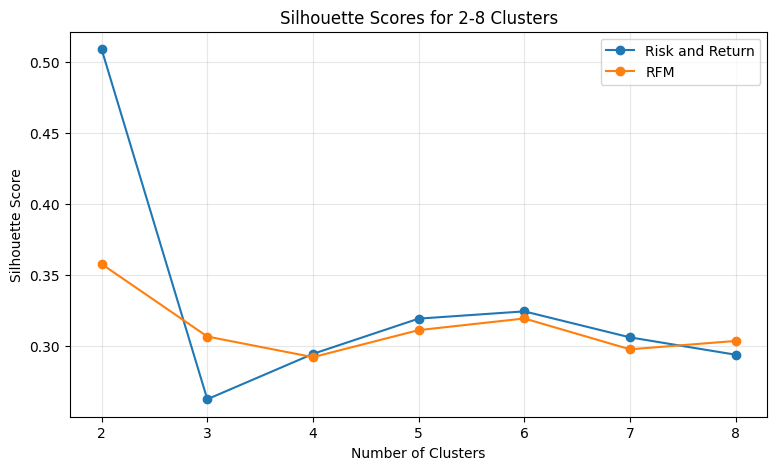

In [34]:
# Part 2.2 - Step 3: Silhouette comparison

plt.figure(figsize=(9, 5))

for name in ['Risk and Return', 'RFM']:
    data = comparison_df[comparison_df['Matrix'] == name]

    plt.plot(
        data['Clusters'],
        data['Silhouette'],
        marker='o',
        label=name
    )

plt.title("Silhouette Scores for 2-8 Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [35]:
# Part 2.2 - Step 4: Cluster profiles

# Provisional cluster counts based on silhouette
best_risk_k = int(
    comparison_df[comparison_df['Matrix'] == 'Risk and Return']
    .sort_values('Silhouette', ascending=False)
    .iloc[0]['Clusters']
)

best_rfm_k = int(
    comparison_df[comparison_df['Matrix'] == 'RFM']
    .sort_values('Silhouette', ascending=False)
    .iloc[0]['Clusters']
)

print("Provisional Risk and Return clusters:", best_risk_k)
print("Provisional RFM clusters:", best_rfm_k)

# Assign cluster labels
risk_labels = cut_tree(
    risk_linkage, n_clusters=best_risk_k
).ravel() + 1

rfm_labels = cut_tree(
    rfm_linkage, n_clusters=best_rfm_k
).ravel() + 1

# Profiles using original feature values
risk_profile = risk_return.copy()
risk_profile['Cluster'] = risk_labels

rfm_profile = rfm_features.copy()
rfm_profile['Cluster'] = rfm_labels

print("\nRisk and Return Cluster Profiles:")
display(risk_profile.groupby('Cluster').mean().round(4))

print("\nRisk and Return Cluster Sizes:")
print(risk_profile['Cluster'].value_counts().sort_index())

print("\nRFM Cluster Profiles:")
display(rfm_profile.groupby('Cluster').mean().round(2))

print("\nRFM Cluster Sizes:")
print(rfm_profile['Cluster'].value_counts().sort_index())

Provisional Risk and Return clusters: 2
Provisional RFM clusters: 2

Risk and Return Cluster Profiles:


,Mean_Weekly_Return,Beta
Cluster,,
1,0.0024,0.9401
2,0.0090,1.5189



Risk and Return Cluster Sizes:
Cluster
1    456
2     36
Name: count, dtype: int64

RFM Cluster Profiles:


,Recency,Frequency,Monetary
Cluster,,,
1,12.33,3.21,3.835661e+10
2,55.53,2.08,4.568673e+10



RFM Cluster Sizes:
Cluster
1    399
2     93
Name: count, dtype: int64


In [36]:
display(comparison_df.round(4))

,Matrix,Clusters,Silhouette,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.5089,36,456
1,Risk and Return,3,0.2627,36,333
2,Risk and Return,4,0.2946,36,177
3,Risk and Return,5,0.3194,36,177
4,Risk and Return,6,0.3245,6,177
5,Risk and Return,7,0.3062,6,177
6,Risk and Return,8,0.2940,6,123
7,RFM,2,0.3578,93,399
8,RFM,3,0.3068,93,252
9,RFM,4,0.2923,43,209


# 2.3 — K-Means Clustering

In [37]:
# Part 2.3 - Step 1: K-Means evaluation

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

kmeans_results = []

for name, X in [('Risk and Return', risk_scaled),
                ('RFM', rfm_scaled)]:

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X)

        kmeans_results.append({
            'Matrix': name,
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'Inertia': model.inertia_,
            'Smallest_Cluster': pd.Series(labels).value_counts().min(),
            'Largest_Cluster': pd.Series(labels).value_counts().max()
        })

kmeans_results_df = pd.DataFrame(kmeans_results)

display(kmeans_results_df.round(4))

,Matrix,k,Silhouette,Inertia,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.3895,626.6633,147,345
1,Risk and Return,3,0.3207,473.7919,122,204
2,Risk and Return,4,0.3249,374.1102,42,169
3,Risk and Return,5,0.3368,315.7584,27,174
4,Risk and Return,6,0.3351,261.8604,7,159
5,Risk and Return,7,0.3328,225.3914,7,146
6,Risk and Return,8,0.3550,193.0976,7,140
7,RFM,2,0.4212,1082.7948,70,422
8,RFM,3,0.3239,810.7590,63,275
9,RFM,4,0.3404,619.1625,60,215


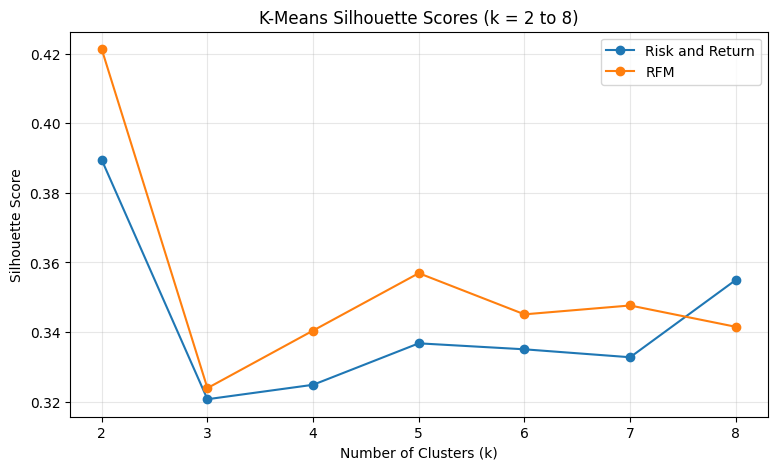

In [38]:

# Part 2.3 - Step 2: Silhouette scores

plt.figure(figsize=(9, 5))

for name in ['Risk and Return', 'RFM']:

    data = kmeans_results_df[
        kmeans_results_df['Matrix'] == name
    ]

    plt.plot(
        data['k'],
        data['Silhouette'],
        marker='o',
        label=name
    )

plt.title("K-Means Silhouette Scores (k = 2 to 8)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


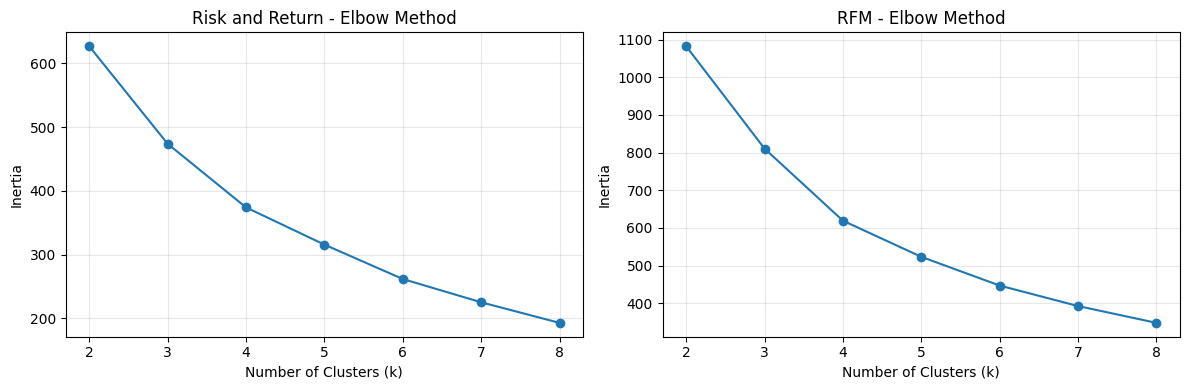

In [39]:

# Part 2.3 - Step 3: Elbow Method

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name in zip(axes, ['Risk and Return', 'RFM']):

    data = kmeans_results_df[
        kmeans_results_df['Matrix'] == name
    ]

    ax.plot(data['k'], data['Inertia'], marker='o')

    ax.set_title(name + " - Elbow Method")
    ax.set_xlabel("Number of Clusters (k)")
    ax.set_ylabel("Inertia")
    ax.set_xticks(range(2, 9))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [40]:
# Part 2.3 - Step 4: Full cluster sizes

for name, X in [('Risk and Return', risk_scaled),
                ('RFM', rfm_scaled)]:

    print("\n", name)

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X)

        sizes = pd.Series(labels + 1).value_counts().sort_index()

        print("k =", k, "| Cluster sizes:", sizes.tolist())


 Risk and Return
k = 2 | Cluster sizes: [345, 147]
k = 3 | Cluster sizes: [122, 166, 204]
k = 4 | Cluster sizes: [149, 42, 132, 169]
k = 5 | Cluster sizes: [174, 27, 109, 131, 51]
k = 6 | Cluster sizes: [110, 119, 41, 56, 159, 7]
k = 7 | Cluster sizes: [86, 48, 7, 146, 82, 74, 49]
k = 8 | Cluster sizes: [76, 80, 29, 76, 44, 40, 7, 140]

 RFM
k = 2 | Cluster sizes: [422, 70]
k = 3 | Cluster sizes: [154, 275, 63]
k = 4 | Cluster sizes: [122, 60, 95, 215]
k = 5 | Cluster sizes: [69, 89, 201, 11, 122]
k = 6 | Cluster sizes: [119, 67, 106, 143, 42, 15]
k = 7 | Cluster sizes: [119, 106, 42, 70, 11, 143, 1]
k = 8 | Cluster sizes: [148, 48, 89, 21, 106, 11, 68, 1]


# 2.4 Cluster profiles and algorithm comparison

In [41]:
# Part 2.4 - Step 1: Final cluster assignments

from scipy.cluster.hierarchy import cut_tree
from sklearn.cluster import KMeans

risk_k = 2
rfm_k = 2

cluster_labels = {}

for name, X, tree, k in [
    ('Risk and Return', risk_scaled, risk_linkage, risk_k),
    ('RFM', rfm_scaled, rfm_linkage, rfm_k)
]:
    agg_labels = cut_tree(tree, n_clusters=k).ravel() + 1

    km_labels = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit_predict(X) + 1

    cluster_labels[name] = {
        'Agglomerative': agg_labels,
        'K-Means': km_labels
    }

In [42]:
# Part 2.4 - Step 2: Original-unit cluster profiles

for name, original in [
    ('Risk and Return', risk_return),
    ('RFM', rfm_features)
]:
    for algorithm, labels in cluster_labels[name].items():

        profiles = original.copy()
        profiles['Cluster'] = labels

        print(f'\n{name} - {algorithm}')
        print('Cluster means:')
        display(profiles.groupby('Cluster').mean().round(4))

        print('Cluster sizes:')
        display(profiles['Cluster'].value_counts().sort_index())


Risk and Return - Agglomerative
Cluster means:


,Mean_Weekly_Return,Beta
Cluster,,
1,0.0024,0.9401
2,0.0090,1.5189


Cluster sizes:


,count
Cluster,
1,456
2,36



Risk and Return - K-Means
Cluster means:


,Mean_Weekly_Return,Beta
Cluster,,
1,0.0018,0.8178
2,0.0054,1.3689


... (6 outputs left out)


RFM - K-Means
Cluster means:


,Recency,Frequency,Monetary
Cluster,,,
1,13.4502,3.1872,3.271447e+10
2,62.9571,1.8429,8.210920e+10


Cluster sizes:


,count
Cluster,
1,422
2,70


RFM PCA explained variance: 0.7949


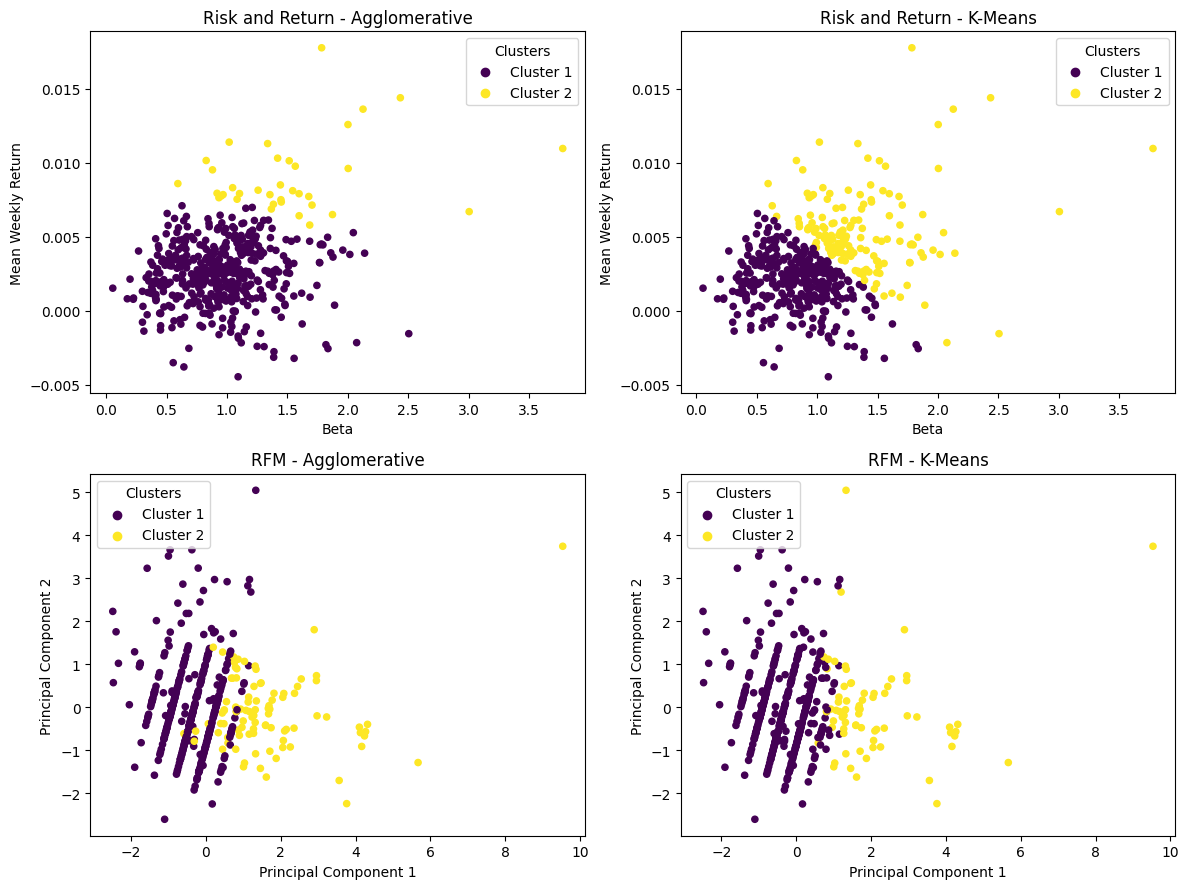

In [43]:
# Part 2.4 - Step 3: Two-dimensional cluster visualisations

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# PCA for RFM visualisation only
pca = PCA(n_components=2)
rfm_2d = pca.fit_transform(rfm_scaled)

print("RFM PCA explained variance:",
      pca.explained_variance_ratio_.sum().round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for col, algorithm in enumerate(['Agglomerative', 'K-Means']):

    # Risk and Return: original units
    axes[0, col].scatter(
        risk_return['Beta'],
        risk_return['Mean_Weekly_Return'],
        c=cluster_labels['Risk and Return'][algorithm],
        cmap='viridis',
        s=20
    )

    axes[0, col].set_title(f'Risk and Return - {algorithm}')
    axes[0, col].set_xlabel('Beta')
    axes[0, col].set_ylabel('Mean Weekly Return')

    # RFM: PCA coordinates
    axes[1, col].scatter(
        rfm_2d[:, 0],
        rfm_2d[:, 1],
        c=cluster_labels['RFM'][algorithm],
        cmap='viridis',
        s=20
    )

    axes[1, col].set_title(f'RFM - {algorithm}')
    axes[1, col].set_xlabel('Principal Component 1')
    axes[1, col].set_ylabel('Principal Component 2')

    for row in range(2):
        axes[row, col].scatter([], [], c='#440154', label='Cluster 1')
        axes[row, col].scatter([], [], c='#FDE725', label='Cluster 2')
        axes[row, col].legend(title='Clusters')

plt.tight_layout()
plt.show()

In [44]:
# Part 2.4 - Step 4: Algorithm membership comparison

from sklearn.metrics import adjusted_rand_score

for name in ['Risk and Return', 'RFM']:

    labels = cluster_labels[name]

    ari = adjusted_rand_score(
        labels['Agglomerative'],
        labels['K-Means']
    )

    print(f'{name} - Adjusted Rand Index: {ari:.4f}')

Risk and Return - Adjusted Rand Index: 0.2072
RFM - Adjusted Rand Index: 0.7411


#### Added: k comparison via profiles and K-means initialisation stability (2.2, 2.3)

In [45]:
from sklearn.cluster import KMeans

def profile(original, labels):
    d = original.copy()
    d['Cluster'] = labels
    out = d.groupby('Cluster').median()
    out['n'] = d.groupby('Cluster').size()
    return out

for name, tree, orig in [('Risk and Return', risk_linkage, risk_return),
                         ('RFM', rfm_linkage, rfm_features)]:
    for k in (2, 4, 5):                       # compare your selected k with richer solutions
        print(f'\n{name} - Ward, k={k} (medians, original units)')
        display(profile(orig, cut_tree(tree, n_clusters=k).ravel() + 1))

# K-means: is the solution stable across initialisations?
for name, X in [('Risk and Return', risk_scaled), ('RFM', rfm_scaled)]:
    for k in (2, 5):
        ref = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        rows = []
        for seed in range(20):
            single = KMeans(n_clusters=k, random_state=seed, n_init=1).fit(X)
            multi = KMeans(n_clusters=k, random_state=seed, n_init=10).fit(X)
            rows.append({'seed': seed,
                         'inertia_n_init1': single.inertia_,
                         'inertia_n_init10': multi.inertia_,
                         'ARI_vs_ref_n_init1': adjusted_rand_score(ref, single.labels_),
                         'ARI_vs_ref_n_init10': adjusted_rand_score(ref, multi.labels_)})
        r = pd.DataFrame(rows)
        print(f'\n{name}, k={k}: inertia range n_init=1 [{r.inertia_n_init1.min():.1f}, '
              f'{r.inertia_n_init1.max():.1f}] vs n_init=10 [{r.inertia_n_init10.min():.1f}, '
              f'{r.inertia_n_init10.max():.1f}]; min ARI vs ref: '
              f'{r.ARI_vs_ref_n_init1.min():.3f} (1 start) / {r.ARI_vs_ref_n_init10.min():.3f} (10 starts)')


Risk and Return - Ward, k=2 (medians, original units)


,Mean_Weekly_Return,Beta,n
Cluster,,,
1,0.002528,0.931461,456
2,0.008024,1.444517,36



Risk and Return - Ward, k=4 (medians, original units)


,Mean_Weekly_Return,Beta,n
Cluster,,,
1,0.000997,1.106612,156
2,0.004097,0.999360,177
3,0.001953,0.518713,123
4,0.008024,1.444517,36



Risk and Return - Ward, k=5 (medians, original units)


,Mean_Weekly_Return,Beta,n
Cluster,,,
1,0.000758,1.030652,111
2,0.004097,0.999360,177
3,0.001953,0.518713,123
4,0.002615,1.501205,45
5,0.008024,1.444517,36


... (3 outputs left out)

,Recency,Frequency,Monetary,n
Cluster,,,,
1,11.0,3.0,1.078591e+10,209
2,11.0,3.0,4.119174e+10,147
3,53.0,2.0,2.084781e+10,93
4,11.0,5.0,1.442997e+10,43



RFM - Ward, k=5 (medians, original units)


,Recency,Frequency,Monetary,n
Cluster,,,,
1,11.0,3.0,1.078591e+10,209
2,11.0,3.0,4.119174e+10,147
3,49.0,2.0,2.013167e+10,83
4,11.0,5.0,1.442997e+10,43
5,102.0,0.0,2.378595e+10,10



Risk and Return, k=2: inertia range n_init=1 [626.7, 772.6] vs n_init=10 [626.7, 626.7]; min ARI vs ref: -0.007 (1 start) / 1.000 (10 starts)

Risk and Return, k=5: inertia range n_init=1 [316.5, 337.9] vs n_init=10 [314.3, 316.5]; min ARI vs ref: 0.363 (1 start) / 0.359 (10 starts)

RFM, k=2: inertia range n_init=1 [1082.8, 1146.2] vs n_init=10 [1082.8, 1082.8]; min ARI vs ref: -0.017 (1 start) / 0.989 (10 starts)

RFM, k=5: inertia range n_init=1 [523.1, 571.3] vs n_init=10 [523.1, 526.5]; min ARI vs ref: 0.330 (1 start) / 0.990 (10 starts)


#### Added: cross-tabs, medians, PCA loadings, labelled plots (2.4)


Risk and Return: Ward vs K-means membership (cluster numbers are arbitrary)


K-Means,1,2
Ward,,
1,345,111
2,0,36



RFM: Ward vs K-means membership (cluster numbers are arbitrary)


K-Means,1,2
Ward,,
1,397,2
2,25,68



Risk and Return - Agglomerative: medians


,Mean_Weekly_Return,Beta,n
Cluster,,,
1,0.002528,0.931461,456
2,0.008024,1.444517,36


... (4 outputs left out)


RFM - K-Means: medians


,Recency,Frequency,Monetary,n
Cluster,,,,
1,11.0,3.0,1.556962e+10,422
2,55.0,2.0,2.308445e+10,70


PCA loadings (what the RFM plot axes mean):


,PC1,PC2
Recency,0.715,0.039
Frequency,-0.644,0.427
Monetary,0.273,0.904


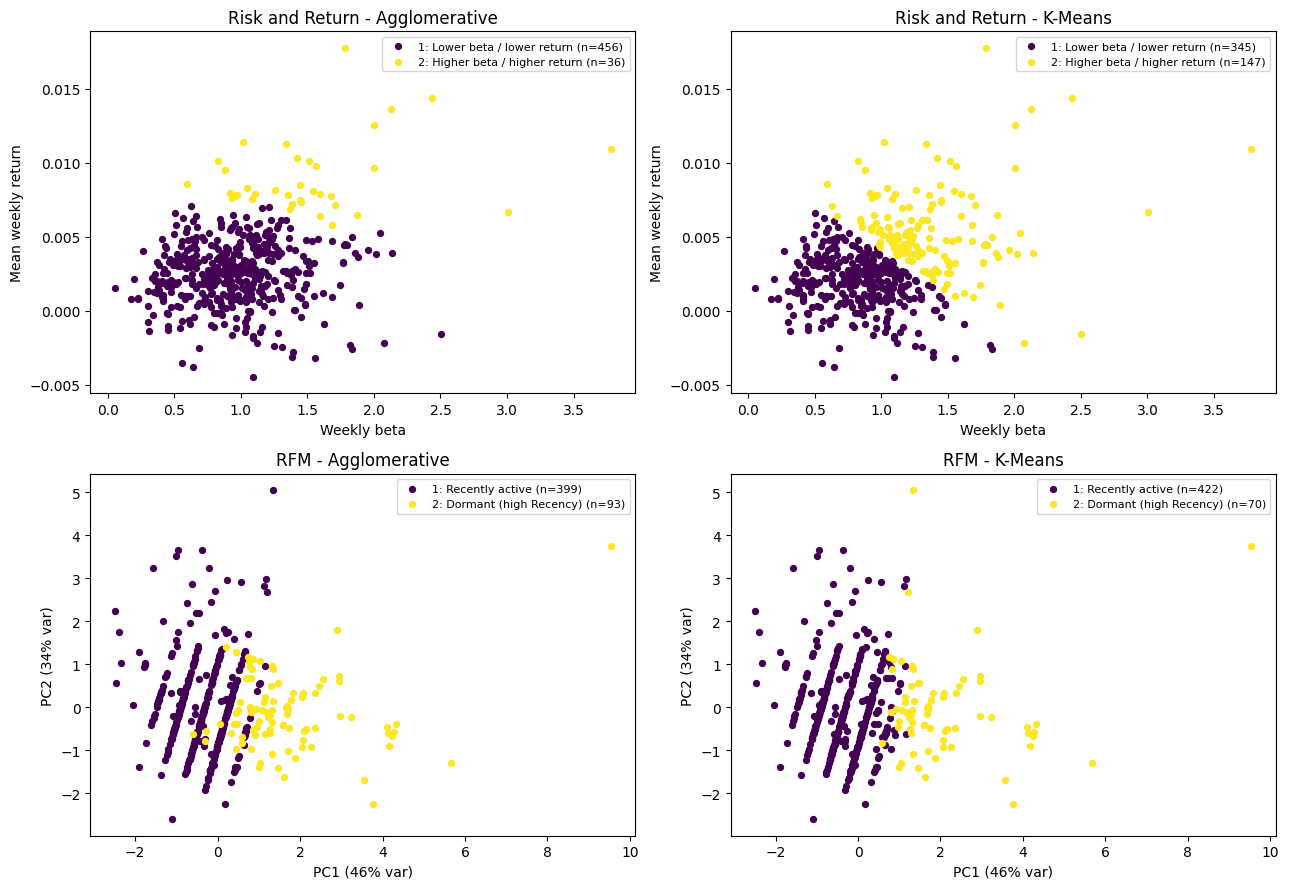

In [46]:
for name in ['Risk and Return', 'RFM']:
    ct = pd.crosstab(cluster_labels[name]['Agglomerative'],
                     cluster_labels[name]['K-Means'],
                     rownames=['Ward'], colnames=['K-Means'])
    print(f'\n{name}: Ward vs K-means membership (cluster numbers are arbitrary)')
    display(ct)

for name, orig in [('Risk and Return', risk_return), ('RFM', rfm_features)]:
    for alg in ['Agglomerative', 'K-Means']:
        print(f'\n{name} - {alg}: medians')
        display(profile(orig, cluster_labels[name][alg]))

print('PCA loadings (what the RFM plot axes mean):')
display(pd.DataFrame(pca.components_.T, index=rfm_scaled.columns,
                     columns=['PC1', 'PC2']).round(3))

# EDIT these names after reading the profile tables above (cluster numbers are arbitrary)
cluster_names = {
    'Risk and Return': {1: 'Lower beta / lower return', 2: 'Higher beta / higher return'},
    'RFM': {1: 'Recently active', 2: 'Dormant (high Recency)'},
}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
colors = {1: '#440154', 2: '#FDE725'}
for col, alg in enumerate(['Agglomerative', 'K-Means']):
    for row, (name, xy, xl, yl) in enumerate([
            ('Risk and Return', (risk_return['Beta'], risk_return['Mean_Weekly_Return']),
             'Weekly beta', 'Mean weekly return'),
            ('RFM', (rfm_2d[:, 0], rfm_2d[:, 1]),
             f'PC1 ({pca.explained_variance_ratio_[0]:.0%} var)',
             f'PC2 ({pca.explained_variance_ratio_[1]:.0%} var)')]):
        labs = cluster_labels[name][alg]
        for c in sorted(set(labs)):
            m = labs == c
            axes[row, col].scatter(np.asarray(xy[0])[m], np.asarray(xy[1])[m], s=18,
                                   c=colors.get(c), label=f'{c}: {cluster_names[name][c]} (n={m.sum()})')
        axes[row, col].set_title(f'{name} - {alg}')
        axes[row, col].set_xlabel(xl); axes[row, col].set_ylabel(yl)
        axes[row, col].legend(fontsize=8)
plt.tight_layout(); plt.show()

# **2.5 RFM sensitivity and correlated inputs**

In [47]:
# 2.5.1 - Correlation analysis

import numpy as np
import pandas as pd

rfm_corr_data = rfm_features.copy()
rfm_corr_data['Monetary'] = np.log1p(rfm_corr_data['Monetary'])
rfm_corr_data = rfm_corr_data.rename(
    columns={'Monetary': 'log1p(Monetary)'}
)

rfm_correlations = rfm_corr_data.corr()

display(rfm_correlations.round(3))

,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.339,0.161
Frequency,-0.339,1.000,0.023
log1p(Monetary),0.161,0.023,1.000


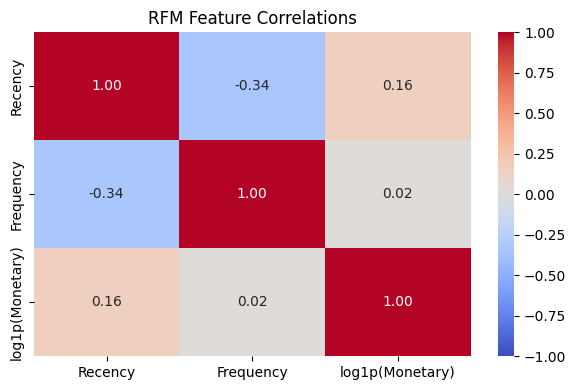

In [48]:
# 2.5.1 - Correlation heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    rfm_correlations,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('RFM Feature Correlations')
plt.tight_layout()
plt.show()

In [49]:
# 2.5.2 - Ward clustering without Monetary

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.metrics import adjusted_rand_score

# Keep only Recency and Frequency
rf_features = rfm_features[['Recency', 'Frequency']].copy()

# Standardise R and F afresh
rf_scaled = StandardScaler().fit_transform(rf_features)

# Ward hierarchical clustering
rf_linkage = linkage(rf_scaled, method='ward')

rf_labels = cut_tree(
    rf_linkage, n_clusters=rfm_k
).ravel() + 1

# Original RFM labels from Section 2.4
original_rfm_labels = cluster_labels['RFM']['Agglomerative']

# Compare membership agreement
rf_ari = adjusted_rand_score(original_rfm_labels, rf_labels)

print('Adjusted Rand Index:', round(rf_ari, 4))
print('Original RFM cluster sizes:')
print(pd.Series(original_rfm_labels).value_counts().sort_index())

print('R and F cluster sizes:')
print(pd.Series(rf_labels).value_counts().sort_index())

Adjusted Rand Index: 0.9525
Original RFM cluster sizes:
1    399
2     93
Name: count, dtype: int64
R and F cluster sizes:
1    400
2     92
Name: count, dtype: int64


In [50]:
# 2.5.2 - Compare traded value profiles

monetary_comparison = pd.DataFrame({
    'Monetary': rfm_features['Monetary'],
    'Original_RFM_Cluster': original_rfm_labels,
    'RF_Only_Cluster': rf_labels
})

print('Original RFM - Average Monetary (USD billions):')
display(
    (monetary_comparison.groupby('Original_RFM_Cluster')['Monetary'].mean() / 1e9).round(2)
)

print('R and F only - Average Monetary (USD billions):')
display(
    (monetary_comparison.groupby('RF_Only_Cluster')['Monetary'].mean() / 1e9).round(2)
)

Original RFM - Average Monetary (USD billions):


,Monetary
Original_RFM_Cluster,
1,38.36
2,45.69


R and F only - Average Monetary (USD billions):


,Monetary
RF_Only_Cluster,
1,37.83
2,48.06


#### Added: skew treatment and sensitivity checks (2.1)

In [51]:
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

def ward_labels(X, k):
    return cut_tree(linkage(X, method='ward', metric='euclidean'), n_clusters=k).ravel()

skew_table = pd.DataFrame({
    'raw': pd.concat([risk_return, rfm_features], axis=1).skew(),
})
skew_table['after_log1p'] = np.log1p(pd.concat([risk_return.clip(lower=0), rfm_features], axis=1)).skew()
print('Skewness before/after log1p (return clipped at 0 only for this diagnostic):')
display(skew_table.round(2))

# Sensitivity: does treating Recency's skew change the Ward RFM partition?
rfm_alt = rfm_prepared.copy()
rfm_alt['Recency'] = np.log1p(rfm_alt['Recency'])
alt_labels = ward_labels(StandardScaler().fit_transform(rfm_alt), rfm_k)
print('ARI, RFM Ward with raw R vs log1p(R):',
      round(adjusted_rand_score(cluster_labels['RFM']['Agglomerative'] - 1, alt_labels), 4))

# Sensitivity: winsorise return and beta at 1st/99th percentile
risk_w = risk_return.clip(risk_return.quantile(0.01), risk_return.quantile(0.99), axis=1)
w_labels = ward_labels(StandardScaler().fit_transform(risk_w), risk_k)
print('ARI, Risk&Return Ward raw vs winsorised (1-99%):',
      round(adjusted_rand_score(cluster_labels['Risk and Return']['Agglomerative'] - 1, w_labels), 4))
# Use these numbers to JUSTIFY your choice (keep raw R / raw return+beta, or switch).

Skewness before/after log1p (return clipped at 0 only for this diagnostic):


,raw,after_log1p
Mean_Weekly_Return,0.94,1.49
Beta,1.25,0.24
Recency,3.62,1.56
Frequency,0.42,-0.93
Monetary,11.67,1.07


ARI, RFM Ward with raw R vs log1p(R): 0.9171
ARI, Risk&Return Ward raw vs winsorised (1-99%): 0.132


#### Added: robust sensitivity evidence for correlations and Monetary removal (2.5)

In [52]:
# Spearman too: R is heavy-tailed and tied, so Pearson alone can mislead
display(rfm_corr_data.corr(method='spearman').round(3))

# Which feature actually drives each Ward partition? (share of variance separated, per feature)
def eta_sq(Xs, labels):
    lab = pd.Series(labels, index=Xs.index)
    tot = ((Xs - Xs.mean()) ** 2).sum()
    bet = sum(len(g) * (g.mean() - Xs.mean()) ** 2 for _, g in Xs.groupby(lab))
    return (bet / tot).round(3)

print('Between-cluster variance share per standardised feature (Ward RFM, selected k):')
display(eta_sq(rfm_scaled, cluster_labels['RFM']['Agglomerative']).to_frame('eta_sq'))

# Traded value profile with medians (means are dragged up by mega-caps)
tv = pd.DataFrame({'M_bn': rfm_features['Monetary'] / 1e9,
                   'Original': original_rfm_labels, 'RF_only': rf_labels})
print('Median traded value (USD bn) by cluster:')
display(tv.groupby('Original')['M_bn'].median().to_frame('Original RFM'))
display(tv.groupby('RF_only')['M_bn'].median().to_frame('R and F only'))

# Is the ARI robust to k?
rf_std = StandardScaler().fit_transform(rfm_features[['Recency', 'Frequency']])
rows = []
for k in range(2, 7):
    rows.append({'k': k, 'ARI_RFM_vs_RF': round(
        adjusted_rand_score(ward_labels(rfm_scaled, k), ward_labels(rf_std, k)), 4)})
display(pd.DataFrame(rows))

,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.185,0.150
Frequency,-0.185,1.000,-0.037
log1p(Monetary),0.150,-0.037,1.000


Between-cluster variance share per standardised feature (Ward RFM, selected k):


,eta_sq
Recency,0.632
Frequency,0.112
Monetary,0.003


Median traded value (USD bn) by cluster:


,Original RFM
Original,
1,15.482182
2,20.847810


,R and F only
RF_only,
1,15.460393
2,20.950200


,k,ARI_RFM_vs_RF
0,2,0.9525
1,3,0.3269
2,4,0.2360
3,5,0.3709
4,6,0.3503


# 3.1

### Task 3.1 Data mart design (max 200 words)
*Write this in the report: grain, facts and dimensions; provenance and calculation history; analytical and stakeholder support.*


Risk and Return - Agglomerative


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
1,4.4,9.4,7.0,3.7,15.6,12.5,15.8,13.8,5.0,6.4,6.4
2,2.8,11.1,0.0,11.1,13.9,2.8,19.4,30.6,2.8,2.8,2.8



Risk and Return - K-Means


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
1,4.3,7.0,9.0,3.2,16.5,16.2,14.5,7.5,5.8,7.8,8.1
2,4.1,15.6,0.7,6.8,12.9,1.4,19.7,32.7,2.7,2.0,1.4



RFM - Agglomerative


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
1,4.3,9.3,6.0,4.8,15.5,12.3,17.5,13.5,4.0,7.5,5.3
2,4.3,10.8,8.6,2.2,15.1,9.7,9.7,21.5,8.6,0.0,9.7



RFM - K-Means


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
1,4.5,9.2,6.4,4.7,15.2,11.8,17.5,14.2,4.3,7.1,5.0
2,2.9,11.4,7.1,1.4,17.1,11.4,7.1,20.0,8.6,0.0,12.9


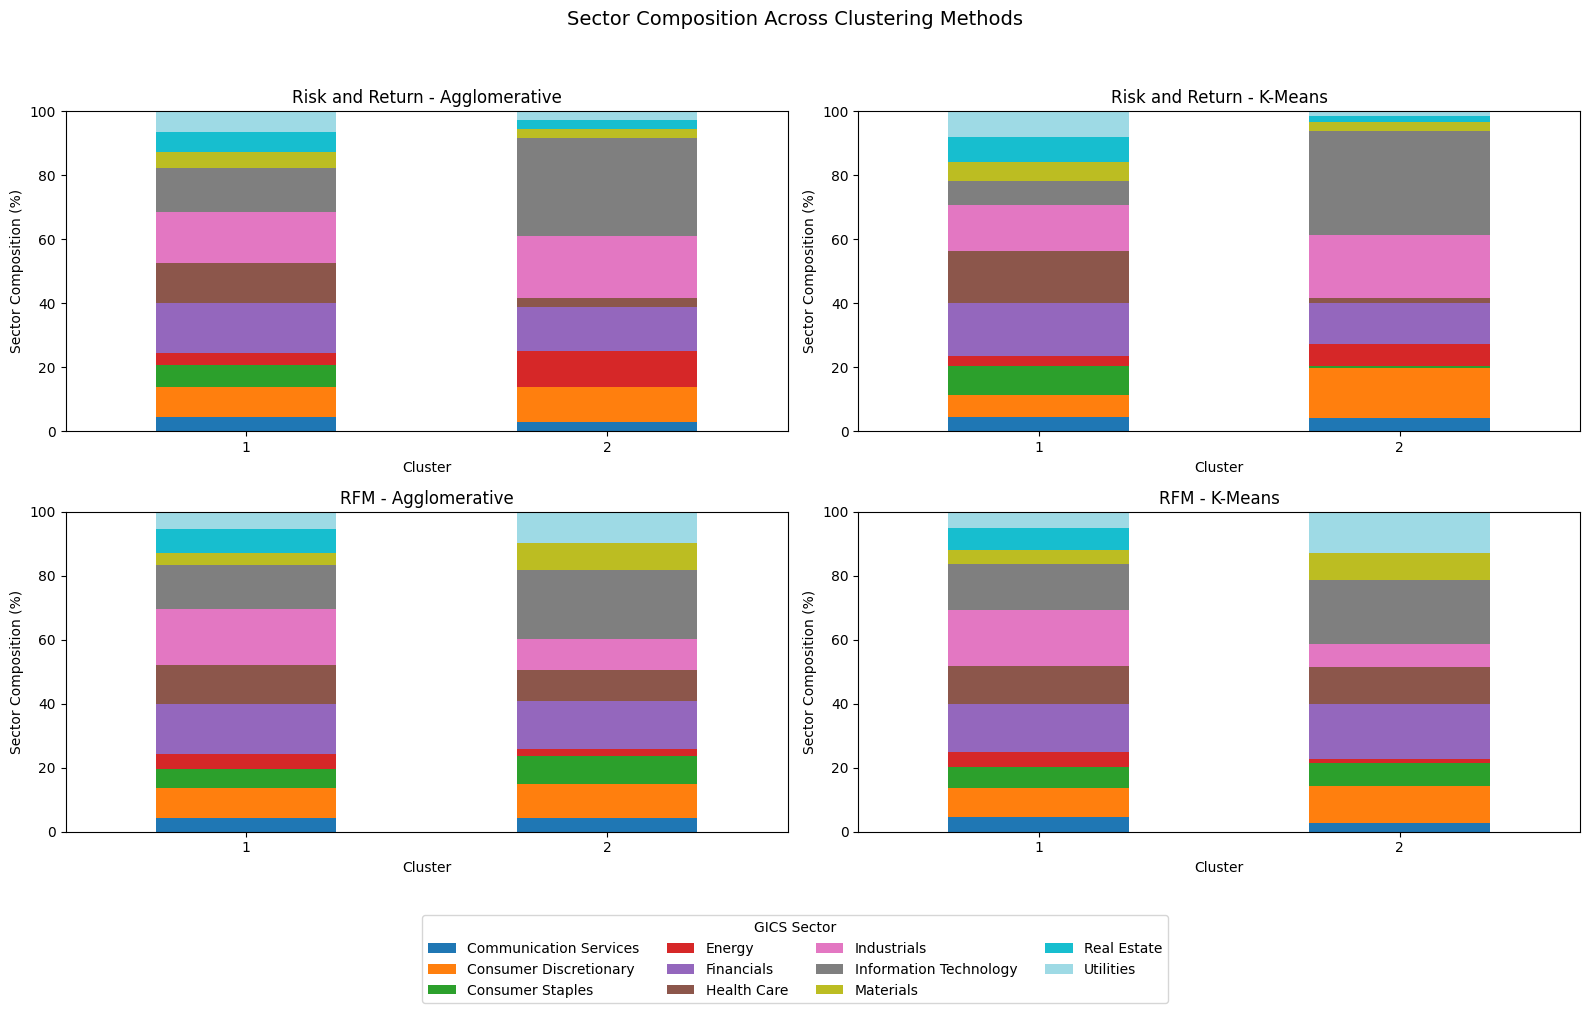

In [53]:
# 3.2.1 - Sector composition for all four clustering solutions

import pandas as pd
import matplotlib.pyplot as plt

# Get sector information from the S&P 500 constituent table
sector_map = sp500_df[['Symbol', 'GICS Sector']].copy()

# Match Yahoo Finance ticker formatting
sector_map['Symbol'] = sector_map['Symbol'].str.replace(
    '.', '-', regex=False
)

sector_map = sector_map.drop_duplicates('Symbol')
sector_map = sector_map.set_index('Symbol')['GICS Sector']

# Original feature matrices and their corresponding labels
matrices = {
    'Risk and Return': risk_return,
    'RFM': rfm_features
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for row, (matrix_name, features) in enumerate(matrices.items()):

    for col, algorithm in enumerate(['Agglomerative', 'K-Means']):

        labels = cluster_labels[matrix_name][algorithm]

        # Match sector data to the exact ticker order
        sector_df = pd.DataFrame({
            'Ticker': features.index,
            'Cluster': labels,
            'Sector': sector_map.reindex(features.index).values
        })

        # Verify that every share has sector information
        if sector_df['Sector'].isna().any():
            missing = sector_df.loc[
                sector_df['Sector'].isna(), 'Ticker'
            ].tolist()
            raise ValueError(f'Missing sectors for: {missing}')

        # Calculate sector percentages within each cluster
        sector_counts = pd.crosstab(
            sector_df['Cluster'],
            sector_df['Sector']
        )

        sector_pct = (
            sector_counts.div(
                sector_counts.sum(axis=1), axis=0
            ) * 100
        )

        print(f'\n{matrix_name} - {algorithm}')
        display(sector_pct.round(1))

        # Visualise sector composition
        sector_pct.plot(
            kind='bar',
            stacked=True,
            ax=axes[row, col],
            colormap='tab20',
            legend=False
        )

        axes[row, col].set_title(
            f'{matrix_name} - {algorithm}'
        )
        axes[row, col].set_xlabel('Cluster')
        axes[row, col].set_ylabel('Sector Composition (%)')
        axes[row, col].set_ylim(0, 100)
        axes[row, col].tick_params(axis='x', rotation=0)

# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='GICS Sector',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.02),
    ncol=4
)

plt.suptitle(
    'Sector Composition Across Clustering Methods',
    fontsize=14
)

plt.tight_layout(rect=[0, 0.10, 1, 0.95])
plt.show()

#### Added: cluster comparison, sector lift, return dependencies (3.2)

In [54]:
from scipy.stats import chi2_contingency

rr = cluster_labels['Risk and Return']['Agglomerative']
rf = cluster_labels['RFM']['Agglomerative']
ct = pd.crosstab(rr, rf, rownames=['Risk&Return (Ward)'], colnames=['RFM (Ward)'])
display(ct)
chi2, p, _, _ = chi2_contingency(ct)
print(f'Chi-square p = {p:.4f}; ARI between the two segmentations = '
      f'{adjusted_rand_score(rr, rf):.3f}')

# Sector LIFT: cluster share / overall share (1.0 = same as the full sample)
overall = sector_map.reindex(risk_return.index).value_counts(normalize=True)
for name, feats in [('Risk and Return', risk_return), ('RFM', rfm_features)]:
    sec = sector_map.reindex(feats.index)
    for alg in ['Agglomerative', 'K-Means']:
        tab = pd.crosstab(cluster_labels[name][alg], sec, normalize='index')
        print(f'\nSector lift - {name} - {alg}')
        display((tab / overall).round(2))

# Return dependencies: average pairwise correlation of weekly returns
Rt = weekly_returns_beta[risk_return.index]
C = Rt.corr(min_periods=100)

def mean_pair(C, a, b=None):
    sub = C.loc[a, a].values if b is None else C.loc[a, b].values
    vals = sub[np.triu_indices_from(sub, k=1)] if b is None else sub.ravel()
    return np.nanmean(vals)

print('\nAverage pairwise weekly-return correlation, all shares:',
      round(mean_pair(C, list(C.index)), 3))
for name, feats in [('Risk and Return', risk_return), ('RFM', rfm_features)]:
    labs = cluster_labels[name]['Agglomerative']
    groups = {c: list(feats.index[labs == c]) for c in sorted(set(labs))}
    for c, mem in groups.items():
        print(f'{name} cluster {c} (n={len(mem)}): within-cluster mean corr = {mean_pair(C, mem):.3f}')
    keys = sorted(groups)
    print(f'{name}: between clusters {keys[0]} and {keys[1]} mean corr = '
          f'{mean_pair(C, groups[keys[0]], groups[keys[1]]):.3f}')
# Similar beta does NOT imply low dependence: compare these with the overall average.

RFM (Ward),1,2
Risk&Return (Ward),,
1,372,84
2,27,9


Chi-square p = 0.4535; ARI between the two segmentations = 0.026

Sector lift - Risk and Return - Agglomerative


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
row_0,,,,,,,,,,,
1,1.03,0.99,1.08,0.87,1.01,1.06,0.98,0.92,1.03,1.04,1.04
2,0.65,1.16,0.00,2.60,0.90,0.24,1.21,2.03,0.57,0.46,0.46



Sector lift - Risk and Return - K-Means


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
row_0,,,,,,,,,,,
1,1.02,0.73,1.38,0.75,1.07,1.38,0.90,0.50,1.19,1.28,1.33
2,0.96,1.64,0.10,1.59,0.84,0.12,1.23,2.17,0.56,0.33,0.22



Sector lift - RFM - Agglomerative


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
row_0,,,,,,,,,,,
1,1.00,0.97,0.92,1.12,1.01,1.04,1.09,0.90,0.82,1.23,0.86
2,1.01,1.13,1.32,0.50,0.97,0.82,0.60,1.43,1.76,0.00,1.59



Sector lift - RFM - K-Means


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
row_0,,,,,,,,,,,
1,1.05,0.97,0.98,1.11,0.98,1.01,1.09,0.95,0.87,1.17,0.82
2,0.67,1.20,1.10,0.33,1.11,0.97,0.44,1.33,1.76,0.00,2.11



Average pairwise weekly-return correlation, all shares: 0.298
Risk and Return cluster 1 (n=456): within-cluster mean corr = 0.302
Risk and Return cluster 2 (n=36): within-cluster mean corr = 0.330
Risk and Return: between clusters 1 and 2 mean corr = 0.272
RFM cluster 1 (n=399): within-cluster mean corr = 0.307
RFM cluster 2 (n=93): within-cluster mean corr = 0.264
RFM: between clusters 1 and 2 mean corr = 0.284


#### Added: export feature table with all cluster assignments

In [55]:
feature_table = risk_return.join(rfm_features)
feature_table['log1p_Monetary'] = np.log1p(feature_table['Monetary'])
feature_table['Weekly_obs'] = weekly_returns_beta.notna().sum().reindex(feature_table.index)
feature_table['Sector'] = sector_map.reindex(feature_table.index)
feature_table['Observation_date'] = observation_date.date()

for tag, name, kk in [('RR', 'Risk and Return', risk_k), ('RFM', 'RFM', rfm_k)]:
    for short, alg in [('Ward', 'Agglomerative'), ('KMeans', 'K-Means')]:
        feature_table[f'{tag}_{short}_k{kk}'] = cluster_labels[name][alg]

# k=3 baselines from Cell 34
feature_table['RR_Ward_k3_baseline'] = risk_agg_labels
feature_table['RR_KMeans_k3_baseline'] = risk_kmeans_labels
feature_table['RFM_Ward_k3_baseline'] = rfm_agg_labels
feature_table['RFM_KMeans_k3_baseline'] = rfm_kmeans_labels

feature_table.index.name = 'Ticker'
feature_table.to_csv('feature_table_with_clusters.csv')
print(feature_table.shape)
display(feature_table.head())

(492, 17)


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary,log1p_Monetary,Weekly_obs,Sector,Observation_date,RR_Ward_k2,RR_KMeans_k2,RFM_Ward_k2,RFM_KMeans_k2,RR_Ward_k3_baseline,RR_KMeans_k3_baseline,RFM_Ward_k3_baseline,RFM_KMeans_k3_baseline
Ticker,,,,,,,,,,,,,,,,,
A,0.001121,1.074724,11,2,1.400180e+10,23.362451,207,Health Care,2024-12-31,1,1,1,1,1,2,1,2
AAPL,0.003930,1.174835,11,2,6.233034e+11,27.158299,207,Information Technology,2024-12-31,1,2,1,1,1,1,3,1
ABBV,0.003749,0.425365,11,3,6.837054e+10,24.948208,207,Health Care,2024-12-31,1,1,1,1,3,3,3,1
ABNB,0.001475,1.472709,11,3,3.652850e+10,24.321359,207,Consumer Discretionary,2024-12-31,1,2,1,1,1,2,3,1
ABT,0.000971,0.583542,11,1,3.523027e+10,24.285172,207,Health Care,2024-12-31,1,1,1,1,3,3,3,1
